# 4. Internal migration: network measures and regionalization

Five-year internal migration flows, 2005–2010, between first-level administrative units
(Data/Migration). Mexico (32 states, 992 flows, with state polygons) and China, with the *Tools*
menu of FlowMapper.org in Python:

* node measures from flows and the network measures of **Tools > Node Measures**,
* top flows,
* community detection (**Tools > Regionalization**: ScLeiden, Leiden, ScLouvain, Louvain) and the
  region flow map built from it.

### Setup

Imports, the data folder, and a few helpers used below: `figure_ground()` (the high-contrast look),
`size_nodes_by_total_flow()`, `show()` / `map_image()` / `show_grid()` (draw maps) and
`compare_settings()` (draw the same map with different settings side by side).

In [1]:
%matplotlib inline
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowmapper_org as fm

# Example data of the FlowMapper GitHub repository (folder "Data"): FLOWMAPPER_DATA, else the
# repository these notebooks live in (python/notebooks -> ../../Data), else a local clone.
_candidates = [os.environ.get("FLOWMAPPER_DATA"), Path.cwd().parent.parent / "Data", r"D:\GitHub\flowmapper\Data"]
DATA = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
assert DATA is not None, ("FlowMapper example data not found: clone https://github.com/geo-social/flowmapper "
                          "and set FLOWMAPPER_DATA to its Data folder")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("flowmapper.org", fm.__version__, "- mirrors FlowMapper.org", fm.FLOWMAPPER_WEB_VERSION)

# ---------------------------------------------------------------------------------------------
# The look used in these notebooks: figure-ground contrast.
#   * flows are the figure: Tapered Fading Arc (TAF), dark colour ramps, full opacity;
#   * regions are the ground: their colours are kept but drawn pale (35 % opacity);
#   * nodes are drawn on top of the flows, dark grey with a white outline.
# figure_ground() only sets ordinary FlowMapper settings, so the projects still open on
# FlowMapper.org. CONTRAST holds two Python-only drawing options (never saved in the file):
#   flow_contrast - raises the opacity of the fading arcs, so small flows stay visible;
#   flow_halo     - a thin white casing that separates flows from the regions below.
# ---------------------------------------------------------------------------------------------
CONTRAST = dict(flow_contrast=0.5, flow_halo=("#ffffff", 0.7))

# Zoom extents (west, south, east, north), a drawing option: render(..., extent=...).
# The legend and title are kept outside the extent.
LOWER48 = (-125, 24, -66.5, 49.5)
EUROPE = (-12, 34, 58, 68)


def us_extent(p):
    """LOWER48 when most of the project's nodes are in the contiguous U.S., else None.

    Every U.S. map in these notebooks is zoomed to the lower 48 (not Alaska and Hawaii):
    map_image() / show() use this whenever no extent is given."""
    ns = p.node_settings
    xf, yf = ns.get("X"), ns.get("Y")
    if p.nodes is None or xf not in p.nodes.columns or yf not in p.nodes.columns:
        return None
    x = pd.to_numeric(p.nodes[xf], errors="coerce")
    y = pd.to_numeric(p.nodes[yf], errors="coerce")
    ok = x.notna() & y.notna()
    if not ok.any():
        return None
    w, s, e, n = LOWER48
    inside = (x[ok].between(w, e) & y[ok].between(s, n)).mean()
    return LOWER48 if inside >= 0.8 else None

# Dark ramps (light end, dark end). The light end is a mid-tone, so the smallest flows
# are still clearly visible; a ColorBrewer ramp such as "Blues" starts almost white.
FLOW_RAMPS = {
    "navy":   ("#4a6fa5", "#0b1f4b"),
    "orange": ("#f16913", "#7f2704"),
    "purple": ("#807dba", "#3f007d"),
    "teal":   ("#3a9e8f", "#00332b"),
}


def figure_ground(p, flows="navy", region_opacity=35, node_color="#3d3d3d"):
    """Pale regions, dark prominent flows, nodes on top (ordinary FlowMapper settings)."""
    lo, hi = FLOW_RAMPS[flows] if flows in FLOW_RAMPS else flows
    p.flow_settings.update(flowStyleName="TAF", clrScheme="Custom", minCustomColor=lo, maxCustomColor=hi,
                           fillOpacity=100)
    p.region_settings.update(fillOpacity=region_opacity, strokeColor="#9e9e9e", strokeWidth=0.4)
    p.node_settings.update(clrScheme="Custom", minCustomColor=node_color, maxCustomColor=node_color,
                           noAttrFillColor=node_color, strokeColor="#ffffff", strokeWidth=0.8, fillOpacity=100)
    p.view_settings["drawingOrder"] = "nodes"          # nodes on top of flows
    return p


def size_nodes_by_total_flow(p, rmin=2, rmax=16, title="Total flow (in + out)", measure="__fm:grossflow"):
    """Circle size = gross flow (in-flow + out-flow), calculated from the flows.

    measure="__fm:inflow" sizes by flow received instead: better when one origin sends
    everything (refugees from one country), where the origin's total would dwarf the rest."""
    p.node_settings.update(ifMapAttribute=True, volume=measure, cfMethod="Proportional",
                           radiusMin=rmin, radiusMax=rmax, legendTitle=title)
    return p


_seen_notices = set()


def map_image(project, contrast=True, **render_options):
    """Draw a project at its own size and return the picture as an array.

    contrast=True adds the CONTRAST drawing options; False draws exactly as FlowMapper.org.
    Legends, title and scale bar are sized in screen pixels, so maps are drawn on their own
    and then tiled, rather than squeezed into small subplot axes."""
    opts = {**(CONTRAST if contrast else {}), **render_options}
    if "extent" not in opts and us_extent(project) is not None:
        opts["extent"] = LOWER48         # U.S. data: the lower 48, never Alaska and Hawaii
    r = project.render(**opts)       # with an extent, the title and legend are kept off the extent
    for n in r.notices:                     # FlowMapper's messages, each shown once
        if n not in _seen_notices:
            _seen_notices.add(n)
            print("notice:", n)
    buf = io.BytesIO()
    r.fig.savefig(buf, format="png")
    buf.seek(0)
    return plt.imread(buf)


def show(project, width=1000, height=700, contrast=True, **render_options):
    """Draw one map in the notebook."""
    show_grid([map_image(project, contrast, width=width, height=height, **render_options)], ncols=1,
              width=width / 70)


def show_grid(images, titles=None, ncols=3, width=22):
    """Tile pictures (arrays from map_image or plt.imread) in a grid."""
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * h / w * nrows + 0.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def compare_settings(base, variants, ncols=3, width=900, height=600, **render_options):
    """Draw copies of `base`, each with some settings changed.

    variants = {"label": {"flow_settings": {...}, "node_settings": {...}, ...}, ...}"""
    images = []
    for label, change in variants.items():
        q = base.copy()
        for block, values in change.items():
            getattr(q, block).update(values)
        images.append(map_image(q, width=width, height=height, **render_options))
    show_grid(images, list(variants), ncols=ncols)

flowmapper.org 0.3.0 - mirrors FlowMapper.org 2.1


<Project 'Mexico internal migration 2005-2010': 32 regions, 32 nodes, 992 flows>


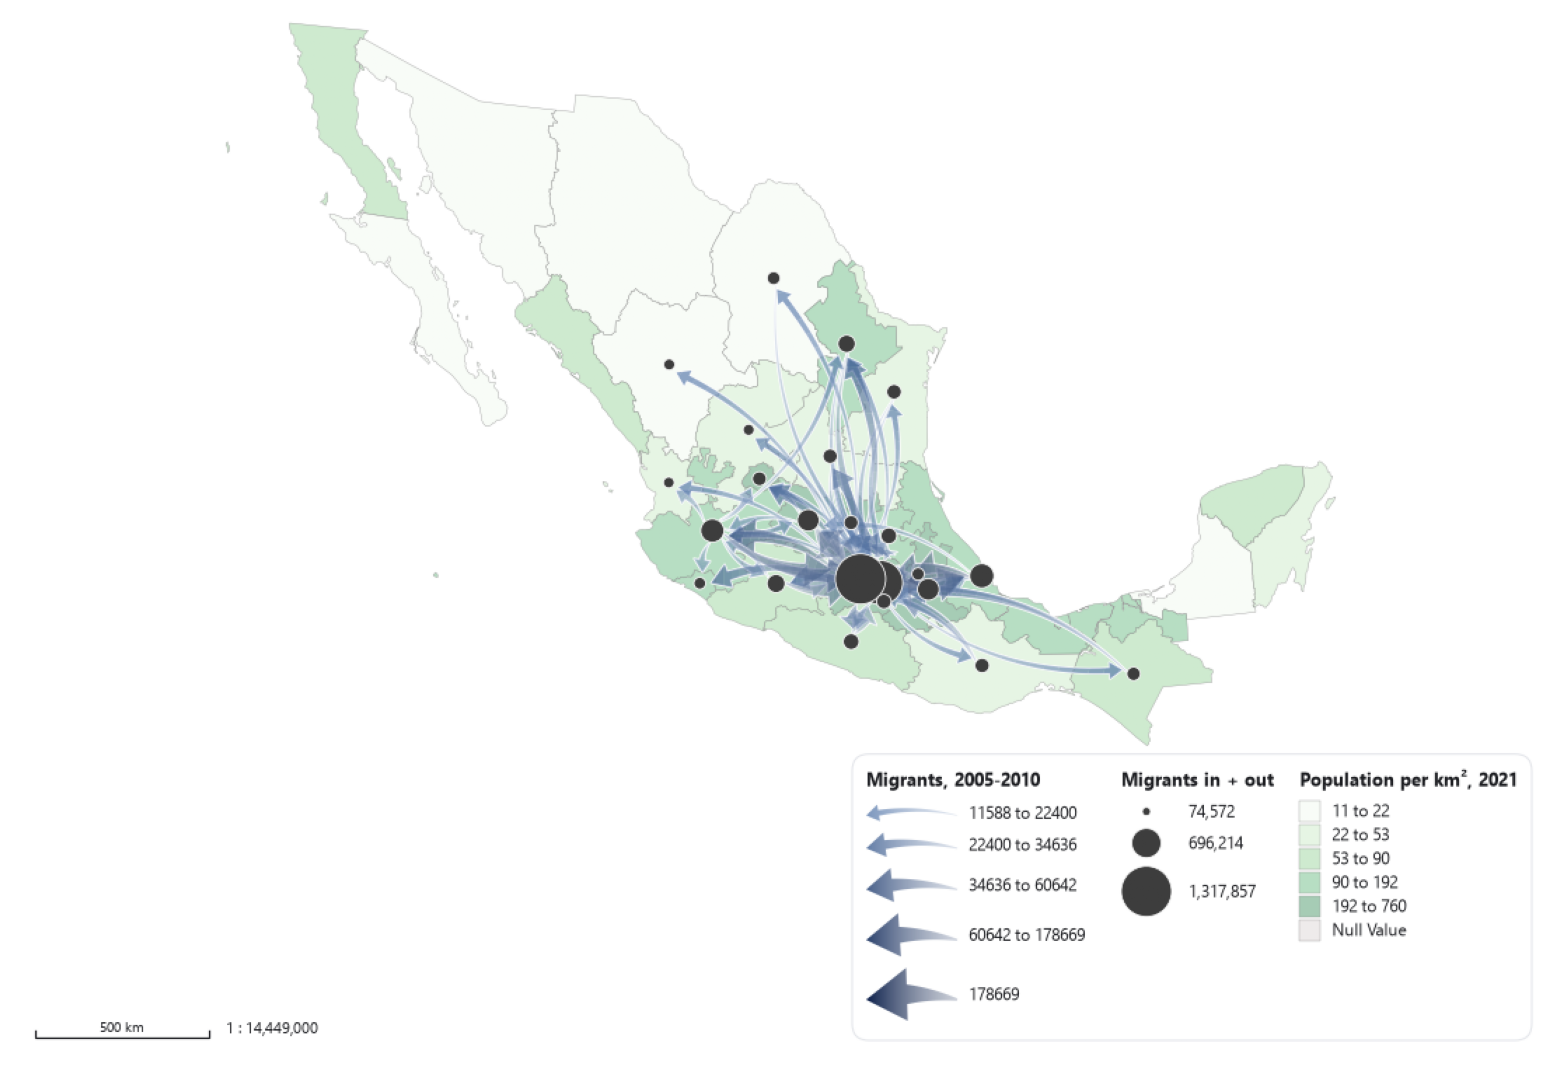

In [2]:
M = DATA / "Migration" / "Americas" / "latin_america" / "MEXICO"
mx = fm.Project.from_data(
    M / "MEX_AdminUnit_Centroids.csv", M / "MEX_5yrs_InternalMigFlows_2010.csv",
    regions=M / "mex_admbnda_adm1_govmex_20210618.json",
    region_table=M / "mex_admpop_adm1_2021_v2.csv",
    name="Mexico internal migration 2005-2010")
mx.basemap_settings["projection"] = "laeaNA"
mx.region_join.update(geoId="ADM1_PCODE", CSVId="ADM1_PCODE", value="PopDensity_sqkm")
mx.region_settings.update(ifMapRegionAttribute=True, attrSource="csv", cfMethod="Quantile", clrScheme="Greens",
                          legendTitle="Population per km², 2021")
mx.flow_settings.update(cfMethod="NaturalBreak", numTopFlows=80, legendTitle="Migrants, 2005-2010")
figure_ground(mx, flows="navy")
size_nodes_by_total_flow(mx, rmin=3, rmax=18, title="Migrants in + out")
print(mx)
show(mx, width=1100, height=750)

## Net migration with a diverging scheme

The same flows with nodes coloured by **net flow** (in − out). The RdBu scheme with five classes
and breaks symmetric around 0 puts a white class in the middle: states that gain and lose about
equally are white, net losers red, net gainers blue. Circle size is the absolute net flow.

breaks: -370000 -92000 -18000 18000 92000 370000
notice: __fm:netflow has negative values (minimum −265,587.55). Circle size shows the absolute value and circle color keeps the sign. A diverging color scheme such as Red-Blue or Purple-Green makes negative and positive values easy to tell apart.


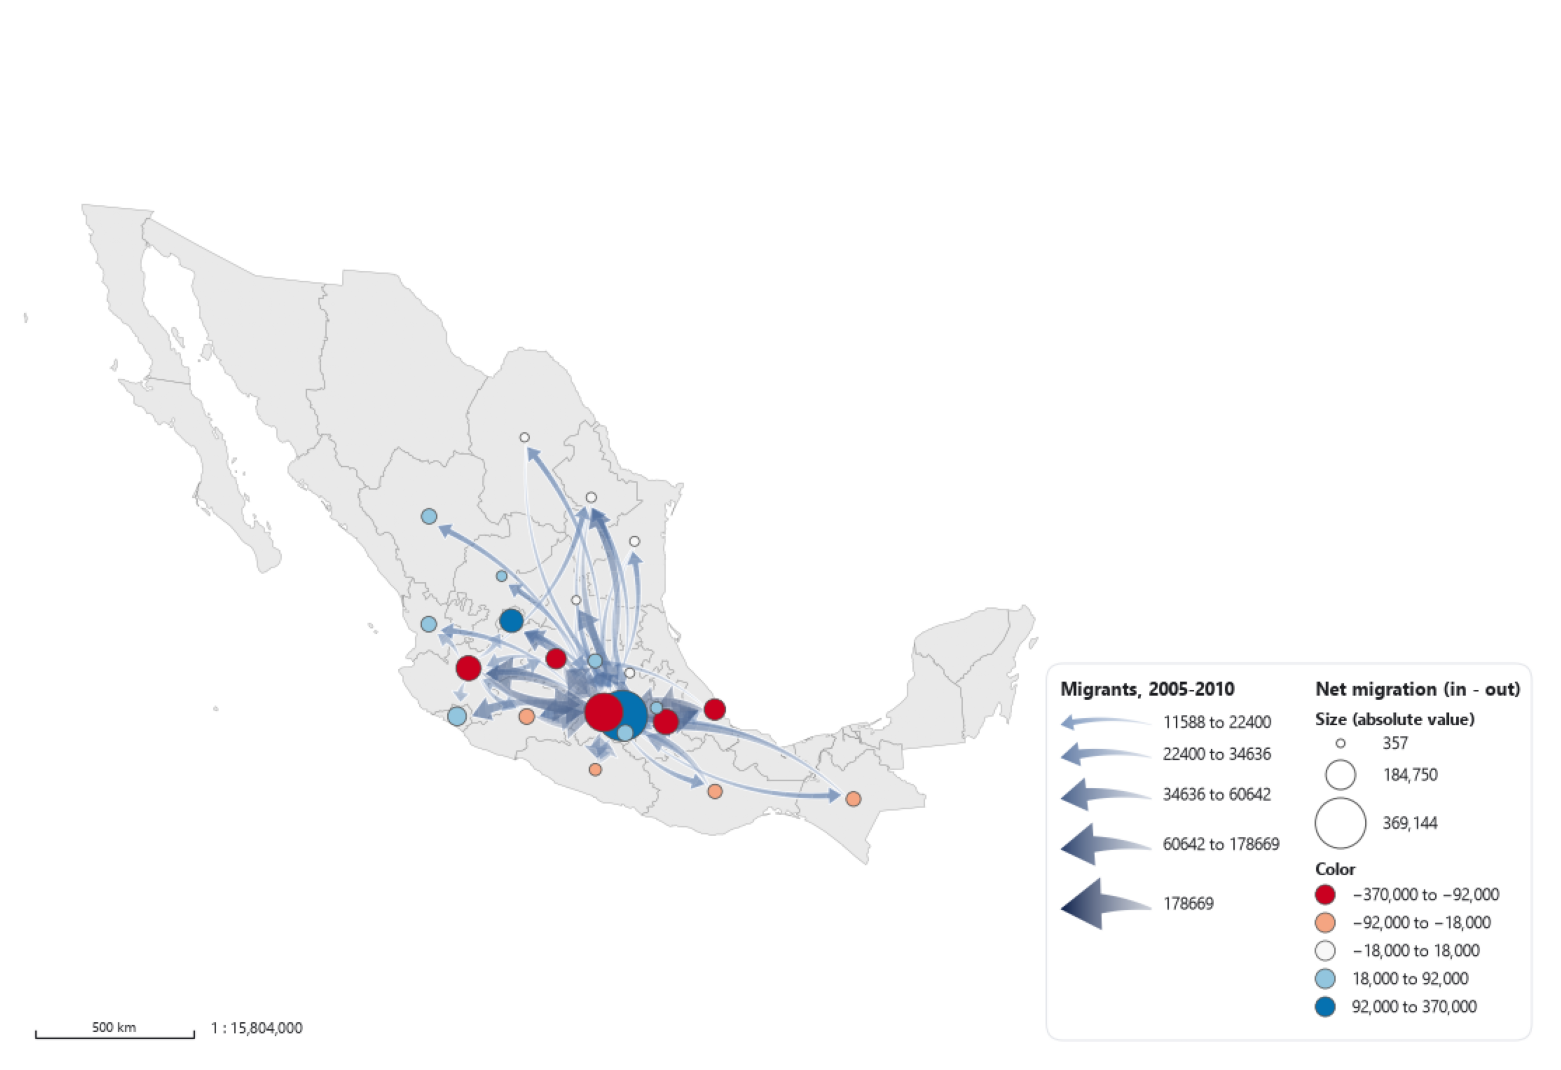

In [3]:
fs = mx.flow_settings
net = fm.node_measures(mx.flows, fs["origin"], fs["destination"], fs["volume"])["netflow"]
Mx = float(np.ceil(net.abs().max() / 1000) * 1000)
a, b = round(Mx / 4, -3), round(Mx / 20, -3)
net_breaks = f"{-Mx:g} {-a:g} {-b:g} {b:g} {a:g} {Mx:g}"
print("breaks:", net_breaks)

nx = mx.copy()
nx.region_settings["ifMapRegionAttribute"] = False
nx.node_settings.update(volume="__fm:netflow", cfMethod="ManualBreak", clrScheme="RdBu", clsNum=5,
                        breakInput=net_breaks, strokeColor="#555555", legendTitle="Net migration (in - out)")
show(nx, width=1100, height=750)

## Node measures

`fm.node_measures` gives the measures of the Nodes tab. `network_node_measures` gives those of
**Tools > Node Measures** (entropy, Gini, degree...). The data folder also has network measures
computed earlier (`MEX_AdminUnit_networkmeasures.csv`), so we can compare them.

In [4]:
m = fm.node_measures(mx.flows, fs["origin"], fs["destination"], fs["volume"])
m.sort_values("netflow").head(5)

,id,inflow,outflow,grossflow,netflow,netflowratio
14,15,526134.734904,791722.282636,1.317857e+06,-265587.547732,-0.201530
20,21,160659.484120,310109.791391,4.707693e+05,-149450.307271,-0.317460
13,14,185764.964600,331276.864406,5.170418e+05,-145511.899806,-0.281432
29,30,216539.285080,329494.806139,5.460341e+05,-112955.521059,-0.206865
10,11,183649.849519,288567.301131,4.722172e+05,-104917.451612,-0.222181


In [5]:
from flowmapper_org.tools import network_node_measures
net_m = network_node_measures(mx.flows)
ref = pd.read_csv(M / "MEX_AdminUnit_networkmeasures.csv")
cmp = net_m.astype({"id": str}).merge(ref.astype({"id": str}), on="id", suffixes=("", "_ref"))
rows = []
for c in net_m.columns[1:]:
    if c + "_ref" in cmp:
        x, y = cmp[c].astype(float), cmp[c + "_ref"].astype(float)
        rows.append({"measure": c, "max abs diff": float(np.max(np.abs(x - y))),
                     "max rel diff": float(np.max(np.abs(x - y) / np.maximum(np.abs(y), 1e-12)))})
pd.DataFrame(rows)

,measure,max abs diff,max rel diff
0,TotalFlow,2.500000e-02,4.578469e-08
1,Inflow,6.250000e-03,5.095033e-08
2,Outflow,1.250000e-02,4.911818e-08
3,Netflow,5.000000e-03,4.556413e-08
4,NetflowRatio,4.957275e-09,7.634223e-08
5,Entropy,2.680435e-08,3.001551e-08
6,InflowEntropy,2.680435e-08,3.001551e-08
7,OutflowEntropy,2.680435e-08,3.001551e-08
8,Gini,2.596283e-08,4.705657e-08
9,InGini,6.067657e-09,2.295376e-08


## Top flows

In [6]:
names = fm.read_csv(M / "mex_admpop_adm1_2021_v2.csv")[["id", "ADM1_EN"]]
top = fm.top_flows(mx.flows, 10, fs["origin"], fs["destination"], fs["volume"])
top = top.merge(names, left_on="ORIGIN", right_on="id").merge(names, left_on="DESTINATION", right_on="id", suffixes=(" origin", " destination"))
top[["ADM1_EN origin", "ADM1_EN destination", "VOLUME"]]

,ADM1_EN origin,ADM1_EN destination,VOLUME
0,México,Distrito Federal,178669.4001
1,Distrito Federal,México,72471.51764
2,Veracruz de Ignacio de la Llave,Distrito Federal,61630.02681
3,Puebla,Distrito Federal,60641.80812
4,Jalisco,Distrito Federal,47549.63751
5,Guanajuato,Distrito Federal,46697.2172
6,Veracruz de Ignacio de la Llave,México,45555.08432
7,Puebla,México,44760.85206
8,México,Veracruz de Ignacio de la Llave,42179.33262
9,Jalisco,México,40931.8185


## Regionalization (community detection)

`fm.detect_communities` runs the regionalization of FlowMapper.org. With the same seed it returns
the same partition as the web site. The spatially constrained methods (`scleiden`, `sclouvain`)
use the state polygons for adjacency.

Mexican migration is dominated by flows to and from Mexico City, so at resolution 1.0 every method
finds only two regions (see the resolution table below). Resolution 1.5 is used here.

In [7]:
RES = 1.5
results = {}
for method in ("scleiden", "leiden", "sclouvain", "louvain"):
    res = fm.detect_communities(mx, method=method, resolution=RES, runs=10, seed=1)
    results[method] = res
    print(f"{method:10s} regions: {res.n_regions:3d}   modularity: {res.modularity:.4f}")

scleiden   regions:   9   modularity: 0.0104
leiden     regions:  16   modularity: 0.0039
sclouvain  regions:   9   modularity: 0.0104
louvain    regions:  16   modularity: 0.0039


In [8]:
res = results["scleiden"]
print(res.summary if not callable(res.summary) else res.summary())
mem = pd.DataFrame(res.membership_records)          # the node table with the region of each node added
region_col = mem.columns[-1]
(mem[["IPUMSID", region_col]].merge(names, left_on="IPUMSID", right_on="id")
    .groupby(region_col)["ADM1_EN"].apply(", ".join).to_frame("states"))

9 regions (ScLeiden (spatially constrained Leiden)) from 32 nodes and 992 flows, best of 10 runs.
Modularity Q = 0.010 (before the spatial step: 0.004)
Spatial contiguity from polygon borders (32 nodes matched; others use Delaunay neighbours): 0 non-contiguous parts split off; 7 small regions merged (one neighbour 0, best modularity gain 7, orphan to smallest neighbour 0).
15% of the flow stays inside regions; 72 region-to-region flows replace 992 flows.


,states
region,
R1,"Distrito Federal, México"
R2,"Campeche, Chiapas, Oaxaca, Quintana Roo, Tabas..."
R3,"Colima, Jalisco, Michoacán de Ocampo, Nayarit"
R4,"Baja California, Baja California Sur, Coahuila..."
R5,"Hidalgo, Puebla, Tlaxcala"
R6,"Nuevo León, San Luis Potosí, Tamaulipas"
R7,"Guanajuato, Querétaro de Arteaga"
R8,"Guerrero, Morelos"
R9,"Aguascalientes, Zacatecas"


`res.to_project()` builds the region project of FlowMapper.org: dissolved region polygons, one node
per region and the flows between regions. The regions are categorical; `Paired` has 12 colours.
A multi-hue region palette leaves no hue free for the flows, so the flows are charcoal.

notice: 16 categories but the scheme has 12 colors: the 5 least frequent categories are shown as "Other". Try Paired or Set 3 (12 colors) for more.


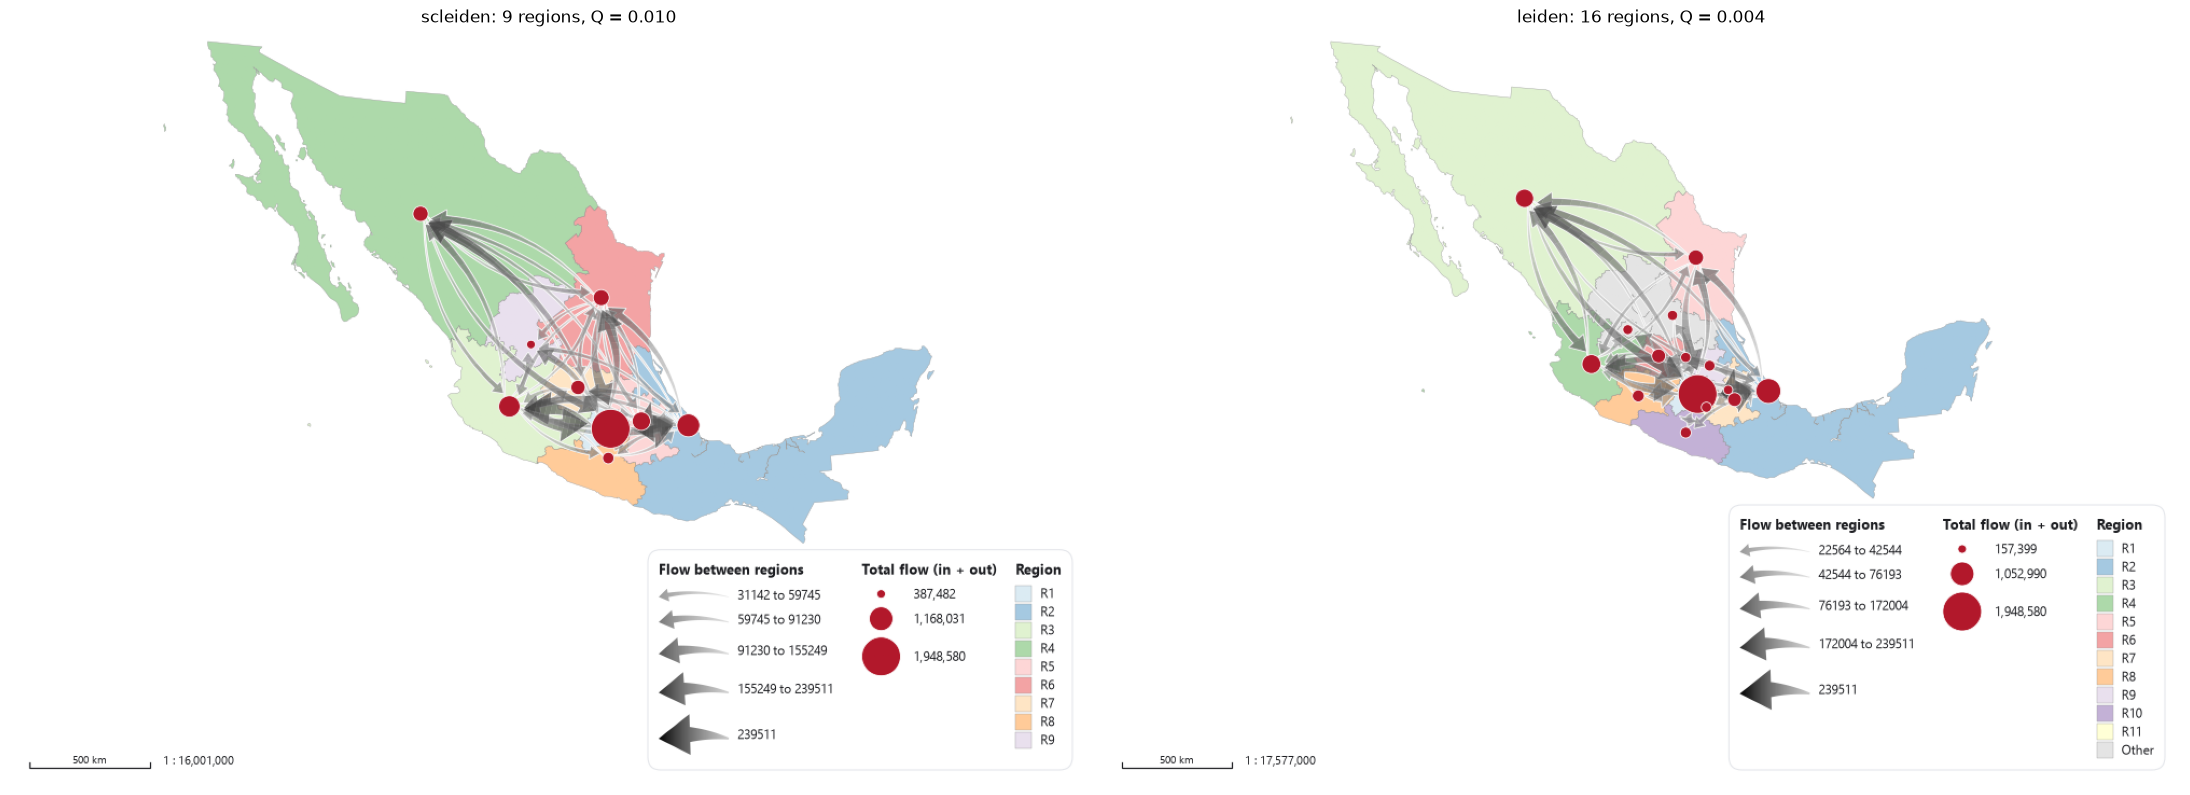

WindowsPath('output/mexico_regions_scleiden.json')

In [9]:
CHARCOAL = ("#737373", "#000000")
images, titles = [], []
for method in ("scleiden", "leiden"):
    rp = results[method].to_project()
    rp.basemap_settings["projection"] = "laeaNA"
    rp.region_settings["clrScheme"] = "Paired"
    rp.flow_settings.update(cfMethod="NaturalBreak", numTopFlows=50)
    figure_ground(rp, flows=CHARCOAL, region_opacity=40, node_color="#b2182b")
    size_nodes_by_total_flow(rp, rmin=4, rmax=18)
    images.append(map_image(rp, width=1000, height=700))
    titles.append(f"{method}: {results[method].n_regions} regions, Q = {results[method].modularity:.3f}")
show_grid(images, titles, ncols=2)
results["scleiden"].to_project().save(OUT / "mexico_regions_scleiden.json")   # open on FlowMapper.org

### Resolution

Higher resolution gives more, smaller regions.

In [10]:
rows = []
for res_ in (0.5, 1.0, 1.5, 2.0, 3.0):
    r = fm.detect_communities(mx, method="scleiden", resolution=res_, runs=10, seed=1)
    rows.append({"resolution": res_, "regions": r.n_regions, "modularity (Q at resolution)": r.modularity})
pd.DataFrame(rows)

,resolution,regions,modularity (Q at resolution)
0,0.5,1,0.000000
1,1.0,2,0.069641
2,1.5,9,0.010359
3,2.0,11,-0.015801
4,3.0,12,-0.023358


## China

The 2010 flow folder has no polygons next to it, so the spatial methods build adjacency from
Voronoi cells of the province centroids.

regions: 4, modularity: 0.1692


notice: The flow file has 12 flows between two different nodes, so "Show top flows" was set to 12.


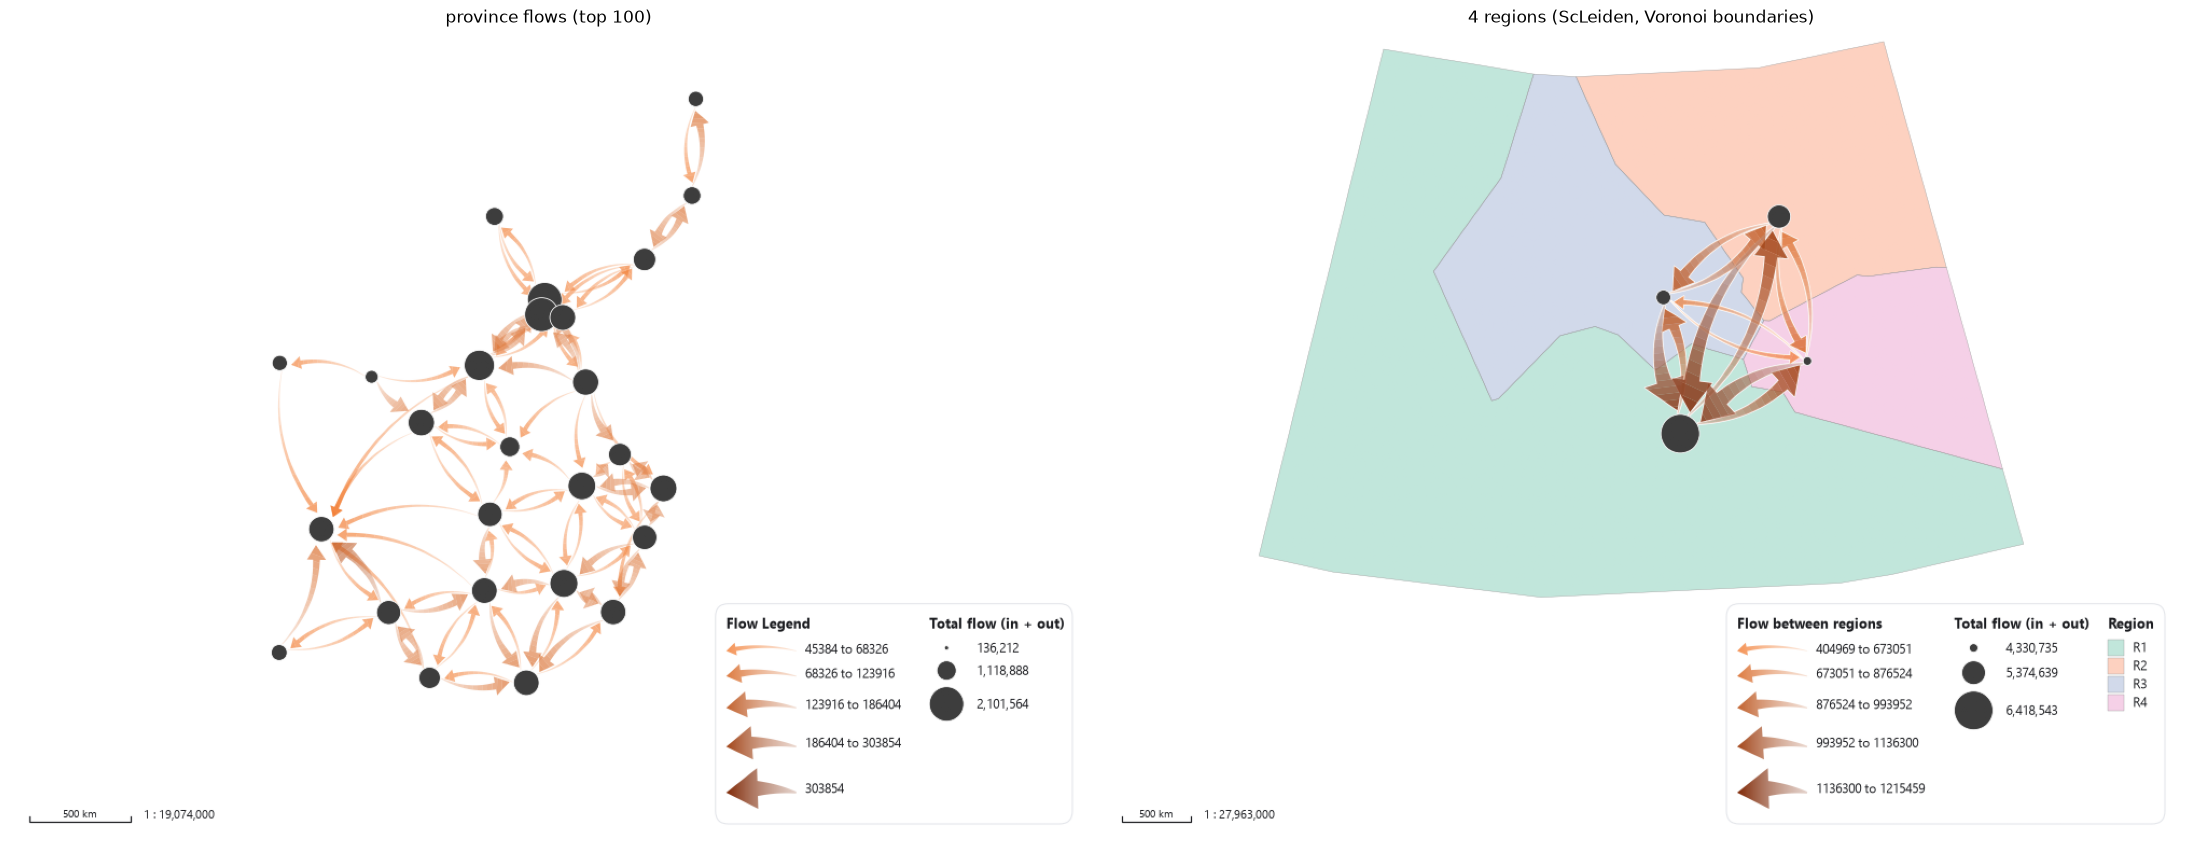

In [11]:
C = DATA / "Migration" / "ASIA" / "CHINA"
cn = fm.Project.from_data(C / "CHN_AdminUnit_Centroids.csv", C / "CHN_5yrs_InternalMigFlows_2010.csv", name="China 2005-2010")
cn.basemap_settings["projection"] = "abEqAreaCn"
cn.flow_settings.update(cfMethod="NaturalBreak", numTopFlows=100)
figure_ground(cn, flows="orange")
size_nodes_by_total_flow(cn)
cres = fm.detect_communities(cn, method="scleiden", resolution=1.0, runs=10, seed=1, boundary="voronoi")
print(f"regions: {cres.n_regions}, modularity: {cres.modularity:.4f}")
rp = cres.to_project()
rp.basemap_settings["projection"] = "abEqAreaCn"
rp.flow_settings["numTopFlows"] = 60
figure_ground(rp, flows="orange", region_opacity=40)
size_nodes_by_total_flow(rp, rmin=4, rmax=18)
show_grid([map_image(cn, width=1000, height=750), map_image(rp, width=1000, height=750)],
          ["province flows (top 100)", f"{cres.n_regions} regions (ScLeiden, Voronoi boundaries)"], ncols=2)

## Flow matrix → flow list

Migration data often comes as an origin × destination matrix. **Tools > Flow Matrix to Flow List**
turns it into the flow table FlowMapper reads. Here a matrix is made from the Rwanda migration flows
and converted back.

In [12]:
from flowmapper_org.tools import convert_flow_matrix_to_flow_list
R = DATA / "Migration" / "AFRICA" / "RWANDA"
rw = pd.read_csv(R / "RWA_5yrs_InternalMigFlows_2010.csv")
matrix = rw.pivot_table(index=rw.columns[0], columns=rw.columns[1], values=rw.columns[2], fill_value=0)
matrix.to_csv(OUT / "rwanda_matrix.csv")
display(matrix.round(0))
convert_flow_matrix_to_flow_list(OUT / "rwanda_matrix.csv", as_frame=True).head()

DESTINATION,1,2,3,4,5,6,7,8,9,10
ORIGIN,,,,,,,,,,
1,0.0,1193.0,1874.0,2794.0,1742.0,3816.0,1267.0,1050.0,9624.0,1346.0
2,1190.0,0.0,1044.0,983.0,1690.0,2085.0,3797.0,599.0,11650.0,4072.0
3,1881.0,1053.0,0.0,2769.0,1979.0,1707.0,943.0,1600.0,3183.0,1185.0
4,2856.0,1009.0,2819.0,0.0,1901.0,3294.0,924.0,1463.0,4356.0,1213.0
5,1637.0,1593.0,1853.0,1756.0,0.0,4229.0,1163.0,1751.0,5894.0,4338.0
6,3741.0,2051.0,1668.0,3171.0,4445.0,0.0,1732.0,1789.0,10854.0,4178.0
7,1262.0,3791.0,936.0,904.0,1235.0,1763.0,0.0,506.0,10853.0,1352.0
8,1914.0,1094.0,2903.0,2617.0,3392.0,3322.0,926.0,0.0,4798.0,2072.0
9,4580.0,5611.0,1521.0,2052.0,3006.0,5310.0,5230.0,1268.0,0.0,5051.0


,Origin,Destination,Volume
0,1,2,1193.078973
1,1,3,1874.152526
2,1,4,2793.930744
3,1,5,1741.512933
4,1,6,3815.591492
